In [ ]:
import tables as tb
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import pyvista as pv
import pathlib
import pandas as pd

In [26]:
import LT_analysis_functions as LT

In [27]:
LT_S1_dir = '../out/xe_lt_s1_3'
S1_cath_dir = '../out/xe_s1_cath'

In [28]:
for path in sorted(pathlib.Path(LT_S1_dir).glob('*.h5')):
    with tb.open_file(path, 'r') as file:
        # print(file.root.MC.sources.read())
        # print(file.root.MC.sources.dtype)
        print(file.root.MC.sources.colnames)
        print(file.root.MC.sensor_hits.colnames)

['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']
['event', 'x', 'y', 'z', 'e', 'n']
['event', 'sensor_id', 'time']


In [29]:
def data_reading_wo_pd(path, table):
    with tb.open_file(path, 'r') as file:
            data = file.root.MC.__getitem__(table).read()
        #     print(data)
            column_names = file.root.MC.__getitem__(table).colnames
    return data, column_names



def full_data_reading_wo_pd(dir_path, table):
    buffer = []
    for path in pathlib.Path(dir_path).glob('*.h5'):
          single_path_data, _ = data_reading_wo_pd(path, table)
          buffer.append(single_path_data)

    stacked_data = np.concatenate(buffer)
    return stacked_data

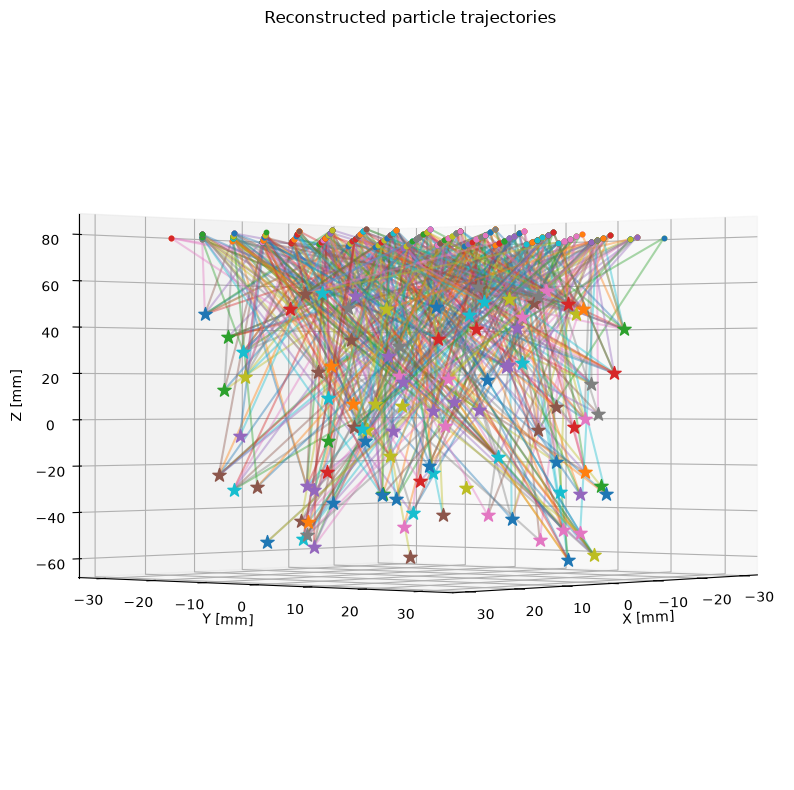

In [30]:
fig, ax = LT.plot_tracks('../out/xe_lt_s1/lt_s1_0000.h5', n_events = 100)

Axes3D.view_init(ax, 0, 40, 0)

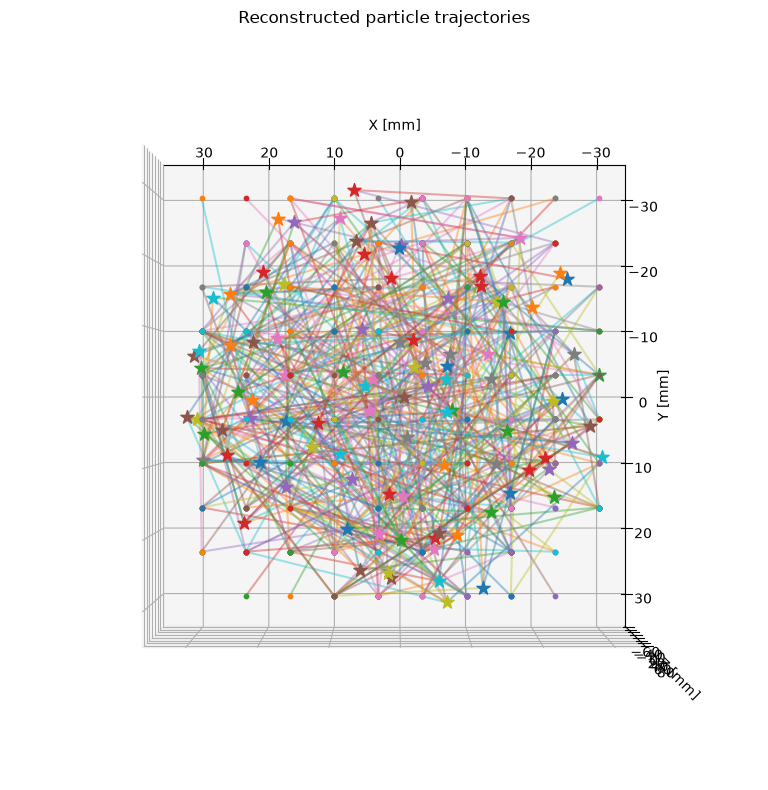

In [31]:
fig, ax = LT.plot_tracks('../out/xe_lt_s1/lt_s1_0000.h5', n_events = 100)

Axes3D.view_init(ax, 90, 90, 0)

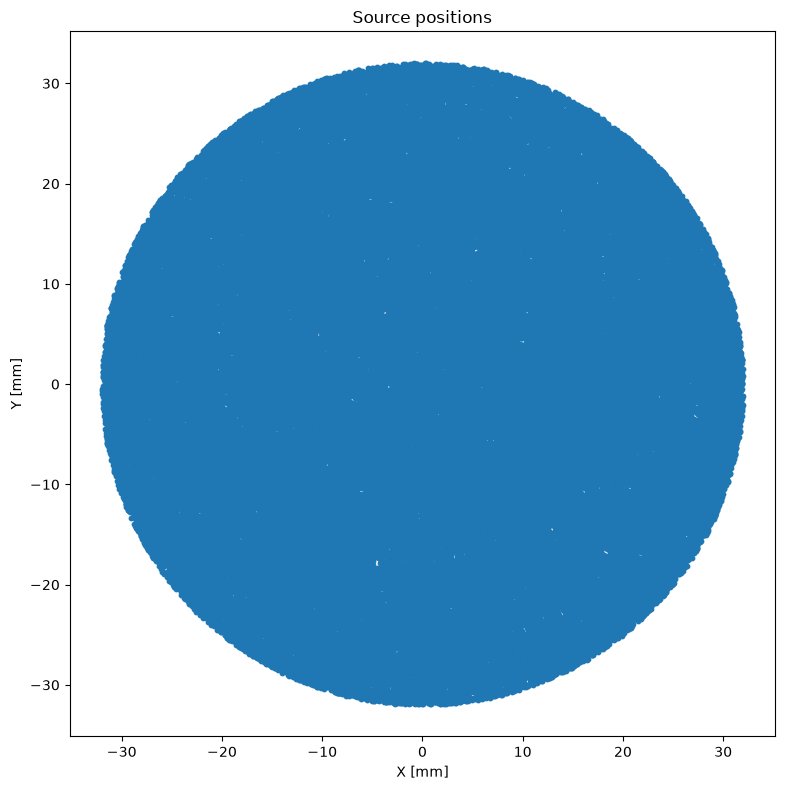

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Source positions'}, xlabel='X [mm]', ylabel='Y [mm]'>)

In [ ]:
LT.plot_sources('../out/xe_lt_s1_3/lt_s1_3_0000.h5', n_events=100000)

In [33]:
def plot_sources_3d(path, n_events=None, seed=None):
    sources, _ = LT.data_reading_wo_pd(path, 'sources')

    if n_events is not None:

        available_events = sources["event"].unique()

        if n_events > len(available_events):
            raise ValueError(
                f"Requested {n_events} events, "
                f"but only {len(available_events)} are available."
            )

        rng = np.random.default_rng(seed)

        selected_events = rng.choice(
            available_events,
            size=n_events,
            replace=False
        )

        sources = sources[
            sources["event"].isin(selected_events)
        ]


    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(sources['x'], sources['y'], sources['z'], s=0.01)

    ax.set_xlabel('X (mm)')
    ax.set_ylabel('Y (mm)')
    ax.set_zlabel('Z (mm)')

    ax.set_title('Source Positions')

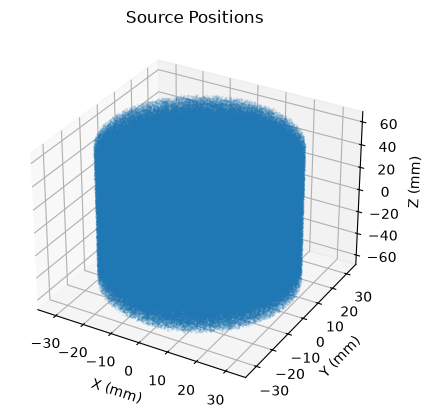

In [34]:
plot_sources_3d('../out/xe_lt_s1_3/xe_lt_s1_3_0000.h5')

[[ -5.512099 -19.37004  -29.355375]]
(12, 3)
[[-10.718943  27.846834  43.836617]]
(42, 3)


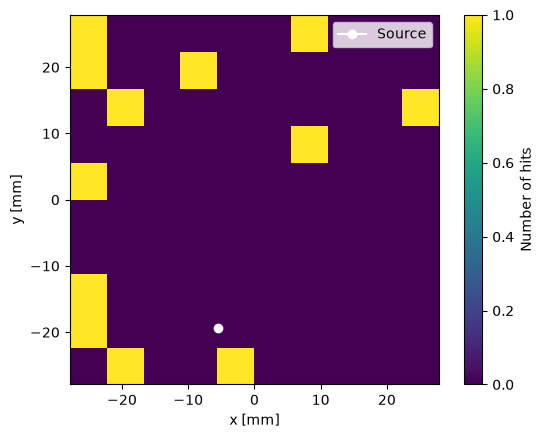

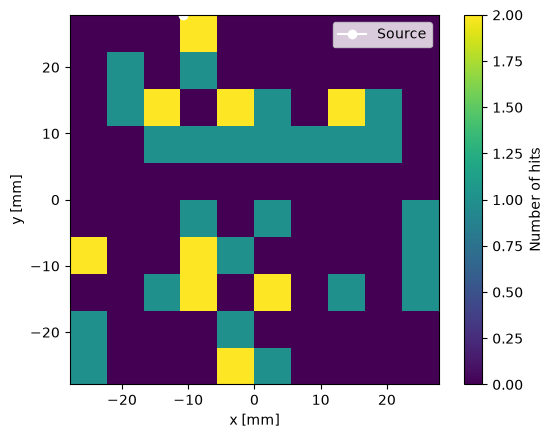

In [35]:
LT.plot_event_hits('../out/xe_lt_s1_3/xe_lt_s1_3_0000.h5', 0)
LT.plot_event_hits('../out/xe_lt_s1_3/xe_lt_s1_3_0000.h5', 1528)

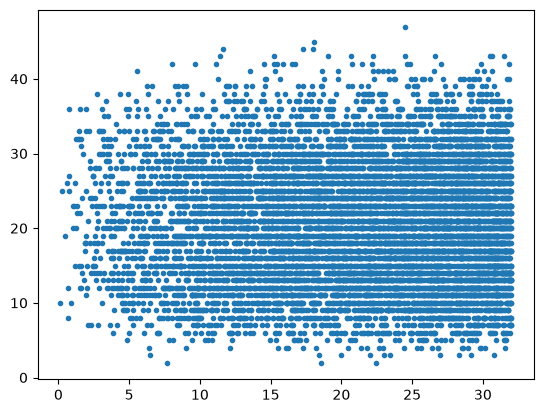

In [36]:
LT.n_evs_vs_R('../out/xe_lt_s1_3/xe_lt_s1_3_0000.h5')

In [37]:
def light_collection_efficiency_s1(dir_path, sensor_id, n_particles=330, n_events=None, n_bins=100):
    sources = full_data_reading_wo_pd(dir_path, 'sources')
    hits = full_data_reading_wo_pd(dir_path, 'sensor_hits')

    if n_events != None:
        sources = sources[:n_events]
        hits = hits[:n_events]

    sensor_mask = hits['sensor_id'] == sensor_id
    sensor_filtered_events = hits[sensor_mask]['event']

    sources_mask = np.isin(sources['event'], sensor_filtered_events, )
    sensor_filtered_sources = sources[sources_mask]

    sensor_filtered_x_sources = sensor_filtered_sources['x']
    sensor_filtered_y_sources = sensor_filtered_sources['y']
    sensor_filtered_z_sources = sensor_filtered_sources['z']  
    hist_sample = np.hstack([sensor_filtered_x_sources.reshape(len(sensor_filtered_x_sources), 1),
                            sensor_filtered_y_sources.reshape(len(sensor_filtered_y_sources), 1),
                            sensor_filtered_z_sources.reshape(len(sensor_filtered_z_sources), 1),] )
    # print(hist_sample.shape)

    source_h , (xedges, yedges, zedges) = np.histogramdd(hist_sample, bins = n_bins)

    events_with_hits, n_hits_per_event_with_hits = np.unique(sensor_filtered_events, return_counts=True )
    
    n_hits = np.zeros(len(sensor_filtered_sources), dtype=int)
    idx = np.searchsorted(events_with_hits, sensor_filtered_sources['event'])

    valid = (
        idx < len(events_with_hits)
    ) & (
        events_with_hits[
            np.clip(idx, 0, len(events_with_hits) - 1)
        ] == sensor_filtered_sources['event']
    )

    n_hits[valid] = n_hits_per_event_with_hits[idx[valid]]

    hit_weighed_h, _ = np.histogramdd(hist_sample, bins = n_bins, weights=n_hits)

    LCE = hit_weighed_h / source_h / n_particles * 100

    LCE[np.isnan(LCE)] = 0

    

    print(np.mean(LCE, axis = (0,1)) )
    fig, axs = plt.subplots(nrows=2, ncols=2)

    axs = axs.flatten()

    for i in range(4):
        im = axs[i].imshow(LCE[:, :, i * int(np.floor(n_bins / 3) )  ].T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])
        plt.colorbar(im, ax=axs[i], label='Collection efficiency (%)')

    plt.tight_layout()

    return LCE[:, :, int(np.floor(n_bins / 2))]

/tmp/ipykernel_80694/4094035348.py:42: RuntimeWarning: invalid value encountered in divide
  LCE = hit_weighed_h / source_h / n_particles * 100


[0.2749585  0.27605473 0.27758608 0.27996118 0.28088852 0.28271494
 0.2848463  0.2859639  0.28807832 0.2898398  0.29226255 0.2936746
 0.29551571 0.29682653 0.29933233 0.30079239 0.30345651 0.3049573
 0.30634646 0.3085836  0.31049631 0.31251817 0.31338521 0.31488963
 0.31414554]


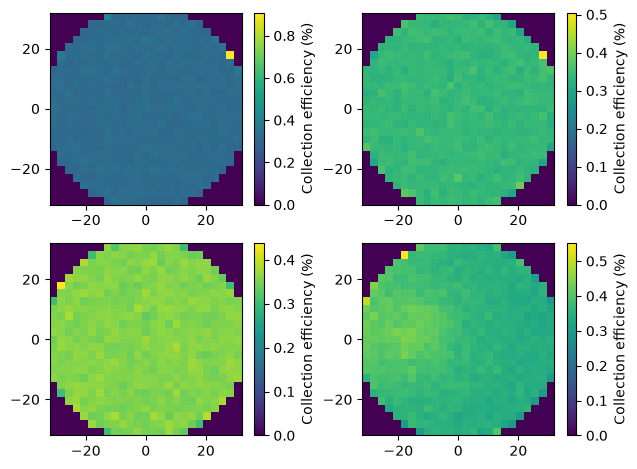

In [38]:
a = light_collection_efficiency_s1(LT_S1_dir, 25, n_bins=25)

In [39]:
def total_light_collection_efficiency_s1(dir_path, n_particles=330, n_events=None, n_bins=100):
    sources = full_data_reading_wo_pd(dir_path, 'sources')
    hits = full_data_reading_wo_pd(dir_path, 'sensor_hits')

    if n_events != None:
        sources = sources[:n_events]
        hits = hits[:n_events]

    hist_sample = np.hstack( [sources['x'].reshape(len(sources['x']), 1),
                            sources['y'].reshape(len(sources['y']), 1),
                            sources['z'].reshape(len(sources['y']), 1) ] )
    print(hist_sample.shape)
    source_h, (xedges, yedges, zedges) = np.histogramdd(hist_sample, bins=[n_bins, n_bins, 2*n_bins])

    events_with_hits, n_hits_per_event_with_hits = np.unique(hits['event'], return_counts=True )
        
    n_hits = np.zeros(len(sources), dtype=int)
    idx = np.searchsorted(events_with_hits, sources['event'])

    valid = (
        idx < len(events_with_hits)
    ) & (
        events_with_hits[
            np.clip(idx, 0, len(events_with_hits) - 1)
        ] == sources['event']
    )

    n_hits[valid] = n_hits_per_event_with_hits[idx[valid]]

    hit_weighed_h, _ = np.histogramdd(hist_sample, bins = [n_bins, n_bins, 2*n_bins], weights=n_hits)

    LCE = hit_weighed_h / source_h / n_particles * 100

    LCE[np.isnan(LCE)] = 0
    
        
    
    print(np.mean(LCE, axis = (0,1)) )
    fig, axs = plt.subplots(nrows=2, ncols=2)

    axs = axs.flatten()

    for i in range(4):
        im = axs[i].imshow(LCE[:, :, i * int(np.floor(2*n_bins / 3) )  ].T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])
        plt.colorbar(im, ax=axs[i], label='Collection efficiency (%)')

    plt.tight_layout()

    return LCE, (xedges, yedges, zedges)

(12000000, 3)


/tmp/ipykernel_80694/3983504678.py:32: RuntimeWarning: invalid value encountered in divide
  LCE = hit_weighed_h / source_h / n_particles * 100


[2.1162426  2.21827041 2.30427416 2.38545045 2.44948433 2.52534175
 2.58386792 2.66079334 2.72024875 2.7893113  2.84419704 2.9074997
 2.97315708 3.02480726 3.09590343 3.15170737 3.21263589 3.26698813
 3.33131049 3.38685425 3.44724949 3.50850786 3.56962024 3.62223612
 3.68232398 3.73962095 3.78901874 3.85720796 3.9106656  3.96894649
 4.01978606 4.07865597 4.13905483 4.20346074 4.25527513 4.30572491
 4.36281057 4.42251643 4.48138701 4.54771414 4.60482429 4.66354018
 4.71457755 4.77729308 4.84055851 4.89066925 4.94394411 5.00717829
 5.06067993 5.12125356 5.17397597 5.23991554 5.29057106 5.35989638
 5.41985137 5.46913839 5.52420908 5.58574101 5.64022856 5.69922706
 5.75915475 5.8184673  5.88844785 5.93848619 5.99284653 6.05742153
 6.10315063 6.16752101 6.23143614 6.29100589 6.34097429 6.39290081
 6.46261517 6.51387272 6.57181835 6.63397263 6.68181501 6.73765495
 6.8092782  6.84879342 6.91169959 6.95952539 7.01557496 7.06687371
 7.11827258 7.15919199 7.21160889 7.2517586  7.30056983 7.33156

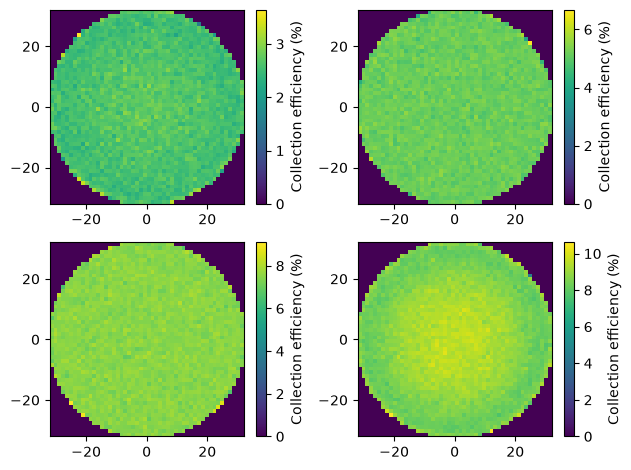

In [40]:
LCE, edges = total_light_collection_efficiency_s1(LT_S1_dir, n_bins=50)

In [41]:
from scipy.optimize import curve_fit

def parabola(x, a, b, c):
    return a + c * (x + b)**2
def plot_LCE_vs_Z(LCE, edges):
    bins_x, bins_y, bins_z = LCE.shape
    xedges, yedges, zedges = edges

    x_idxs = [ bins_x // 2, 3 * bins_x // 4, -2]
    LCEs_1 = LCE[bins_x // 2, bins_y // 2, :]
    LCEs_2 = LCE[3 * bins_x // 4, bins_y // 2, :]
    LCEs_3 = LCE[-2, bins_y // 2, :]

    z_poss = np.linspace(zedges[0], zedges[-1], bins_z)
    x_poss = np.linspace(xedges[0], xedges[-1], bins_x)
    y_poss = np.linspace(yedges[0], yedges[-1], bins_y)

    fig, axs = plt.subplots(nrows=1, ncols=3)

    for i in range(3):
        axs[i].plot(z_poss, LCE[x_idxs[i], bins_y // 2, :], '.')
        axs[i].set_title(f'bin in possition \n({x_poss[x_idxs[i]]:.2f}, {y_poss[bins_y // 2]:.2f})')
        axs[i].set_xlabel('z (mm)')
        axs[i].set_ylabel('LCE (%)')

        a, b, c = np.polyfit(z_poss, LCE[x_idxs[i], bins_y // 2, :], 2)
        #axs[i].plot(z_poss, a * z_poss ** 2 + b * z_poss + c, 'r-')


    fig.suptitle('LCE vs z position')


    plt.tight_layout()

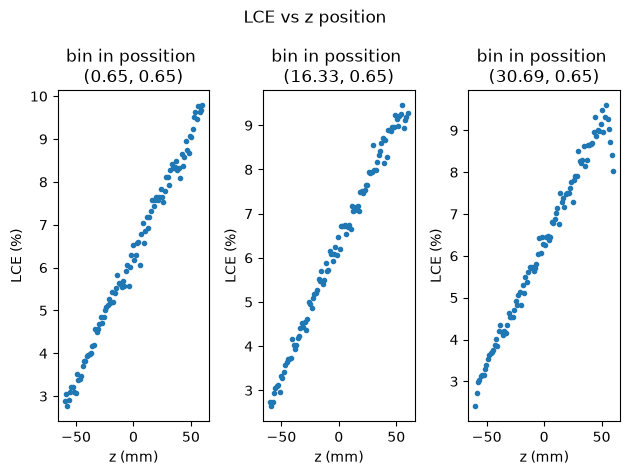

In [42]:
plot_LCE_vs_Z(LCE, edges)


In [43]:
x,y,z = edges

In [44]:
z


array([-5.99999886e+01, -5.87999878e+01, -5.75999908e+01, -5.63999901e+01,
       -5.51999893e+01, -5.39999924e+01, -5.27999916e+01, -5.15999908e+01,
       -5.03999939e+01, -4.91999931e+01, -4.79999924e+01, -4.67999954e+01,
       -4.55999947e+01, -4.43999939e+01, -4.31999969e+01, -4.19999924e+01,
       -4.07999954e+01, -3.95999985e+01, -3.83999939e+01, -3.71999969e+01,
       -3.59999962e+01, -3.47999954e+01, -3.35999985e+01, -3.23999977e+01,
       -3.11999989e+01, -3.00000000e+01, -2.87999992e+01, -2.75999985e+01,
       -2.64000015e+01, -2.52000008e+01, -2.40000000e+01, -2.28000031e+01,
       -2.16000023e+01, -2.04000015e+01, -1.92000046e+01, -1.80000038e+01,
       -1.68000031e+01, -1.56000061e+01, -1.44000053e+01, -1.32000046e+01,
       -1.20000038e+01, -1.08000069e+01, -9.60000610e+00, -8.40000534e+00,
       -7.20000839e+00, -6.00000763e+00, -4.80000687e+00, -3.60000992e+00,
       -2.40000916e+00, -1.20000839e+00, -1.14440918e-05,  1.19998932e+00,
        2.39999008e+00,  

[[ 0.  0. 60.]]
(5305, 3)


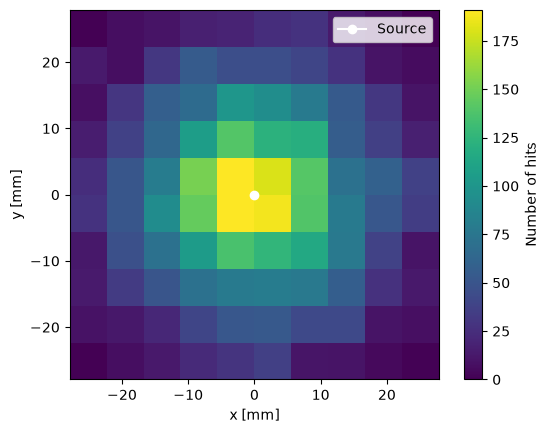

In [45]:
LT.plot_event_hits('../out/xe_s1_cath_full_drift/xe_s1_cath_full_drift_0000.h5', 0)

[[10.666667  0.       60.      ]]
(4986, 3)


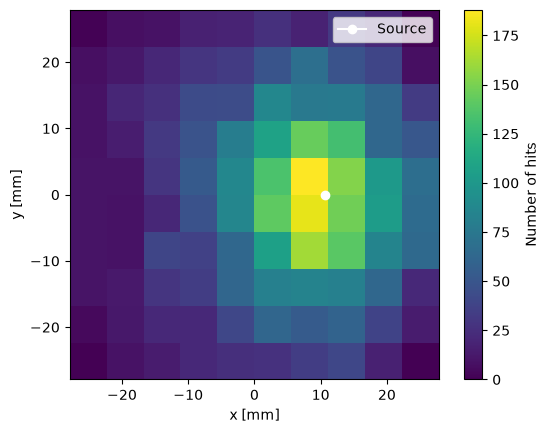

In [46]:
LT.plot_event_hits('../out/xe_s1_cath_3_full_drift/xe_s1_cath_3_full_drift_0000.h5', 0)

[[21.333334  0.       60.      ]]
(4052, 3)


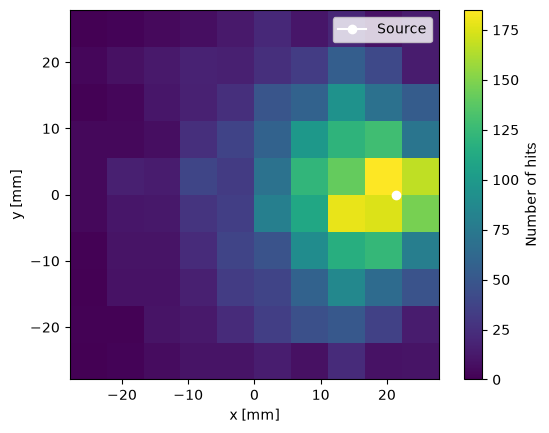

In [47]:
LT.plot_event_hits('../out/xe_s1_2_cath_3_full_drift/xe_s1_2_cath_3_full_drift_0000.h5', 0)

[[32.  0. 60.]]
(2513, 3)


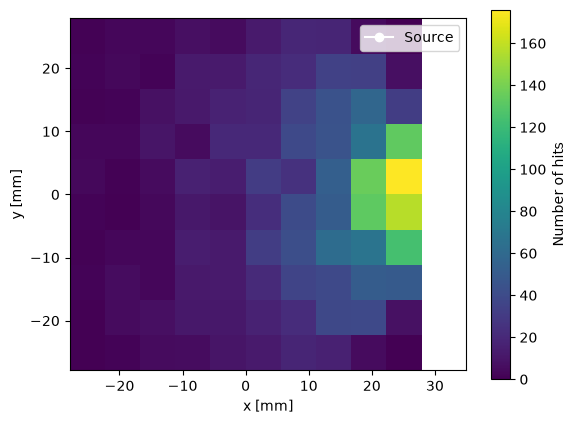

In [48]:
LT.plot_event_hits('../out/xe_s1_3_cath_3_full_drift/xe_s1_3_cath_3_full_drift_0000.h5', 0)